# Klasifikasi Domain Berbasis Punycode untuk Identifikasi Serangan Phishing Menggunakan Naive Bayes

## Studi eksperimen dengan data sintetis dan nyata

Notebook ini merupakan dokumen eksperimen utama sekaligus dokumentasi penelitian. Alur mencakup kajian penelitian terdahulu, audit data, pembentukan data sintetis, EDA, preprocessing, feature engineering URL/Punycode, perbandingan keluarga Naive Bayes, evaluasi real-only, penyimpanan model, dan pengujian prediksi.

## 1. Penelitian terdahulu dan posisi penelitian

| Penelitian | Cara mendeteksi | Keterbatasan/celah yang diambil |
|---|---|---|
| Le et al. (2018), **URLNet** | CNN pada karakter dan kata URL untuk mempelajari representasi URL secara end-to-end. | Kuat untuk pola URL umum, tetapi Punycode/homograph bukan fokus eksplisit dan komputasinya lebih berat daripada Naive Bayes. |
| Mamun et al. (2019), **Using Lexical Features for Malicious URL Detection** | Fitur leksikal URL untuk keputusan real-time tanpa memuat halaman. | Fokus malicious URL umum; hubungan skrip Unicode, IDNA, dan homograph perlu lapisan khusus. |
| Suzuki et al. (2019), **ShamFinder** | Membentuk basis data homoglyph otomatis dan mencari IDN yang menyerupai domain lain. | Sangat relevan untuk homograph, tetapi bukan klasifikasi phishing URL lengkap dengan path/query. |
| Sawabe et al. (2019) | OCR membandingkan tampilan IDN dengan domain legitimate sehingga tidak hanya bergantung pada tabel manual. | Memerlukan pemrosesan visual/OCR; penelitian ini memilih skeleton Unicode yang lebih ringan. |
| Yazdani et al. (2020) | Tabel homoglyph yang diperluas + karakteristik domain + active DNS measurements. | Membutuhkan data DNS aktif; penelitian ini sengaja dapat berjalan offline hanya dari URL. |
| Hu et al. (2021) | Mengevaluasi kebijakan browser terhadap mixed-script, skeleton, confusable, dan tampilan Punycode. | Pertahanan browser tidak selalu sama dan bukan model klasifikasi data phishing. |
| Tupsamudre et al. (2021), **PhishMatch** | Pertahanan berlapis: exact/approximate string matching, n-gram, whitelist, konteks, dan ML. | Menguatkan alasan pendekatan berlapis; penelitian ini memfokuskan kontribusi pada IDN/Punycode dan Naive Bayes ringan. |

### Sumber primer

1. [URLNet, arXiv:1802.03162](https://arxiv.org/abs/1802.03162)  
2. [Using Lexical Features for Malicious URL Detection, arXiv:1910.06277](https://arxiv.org/abs/1910.06277)  
3. [ShamFinder, arXiv:1909.07539](https://arxiv.org/abs/1909.07539)  
4. [Detection Method of Homograph IDNs with OCR](https://www.jstage.jst.go.jp/article/ipsjjip/27/0/27_536/_article/-char/en)  
5. [A Case of Identity, DOI 10.1109/EuroSPW51379.2020.00082](https://doi.org/10.1109/EuroSPW51379.2020.00082)  
6. [Assessing Browser-level Defense against IDN-based Phishing, USENIX Security 2021](https://www.usenix.org/conference/usenixsecurity21/presentation/hu-hang)  
7. [PhishMatch, arXiv:2112.02226](https://arxiv.org/abs/2112.02226)

### Kebaruan yang diuji

Penelitian ini tidak menyatakan semua Punycode sebagai phishing. URL umum dipelajari dengan TF-IDF character n-gram dan indikator struktur URL menggunakan Naive Bayes. Punycode ditambahkan sebagai fokus melalui data IDN legitimate dan homograph phishing yang seimbang, decoding IDNA, identifikasi skrip, serta skeleton confusable. Dengan demikian, keluaran tetap satu label—legitimate atau phishing—tetapi keputusannya menggunakan bukti statistik dan guard Unicode.

## 2. Import dan konfigurasi eksperimen

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import html, ipaddress, json, random, re, unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, average_precision_score,
    classification_report, confusion_matrix, precision_recall_fscore_support,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB

ROOT = Path.cwd()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 100)
print('Folder penelitian:', ROOT)

Folder penelitian: D:\Gumelar Akhirul\Coding\ProjectHibah_NaiveBayes


**Interpretasi:** seed dibuat tetap agar sampling dan split dapat direplikasi. Semua algoritma yang dibandingkan masih berada dalam keluarga Naive Bayes sesuai ruang lingkup judul.

## 3. Generator data sintetis (reproducible)

In [2]:
# Reproducible synthetic-data generator (disabled because CSV final already exists).
import csv

LIMIT = 50_000
SCRIPTS = {
    "cyrillic": ["магазин", "новости", "почта", "книга", "музыка", "город"],
    "greek": ["παράδειγμα", "αγορά", "μουσική", "βιβλίο", "ταξίδι", "πόλη"],
    "armenian": ["օրինակ", "խանութ", "երաժշտություն", "գիրք", "քաղաք"],
    "thai": ["ตัวอย่าง", "ร้านค้า", "หนังสือ", "ดนตรี", "เมือง"],
}
CONFUSABLES = {
    "a":["а","α"], "c":["с"], "e":["е","ε"], "i":["і","ι"], "l":["ӏ"],
    "o":["о","ο","օ"], "p":["р","ρ"], "s":["ѕ"], "x":["х","χ"], "y":["у"]
}
TLDS = ["com","net","org","info","online","site"]

def encode_idn(label):
    return label.encode("idna").decode("ascii")

def mutate_homograph(label, rng):
    positions = [i for i,c in enumerate(label) if c in CONFUSABLES]
    chosen = set(rng.sample(positions, rng.randint(1, min(3,len(positions)))))
    return "".join(rng.choice(CONFUSABLES[c]) if i in chosen else c
                   for i,c in enumerate(label))

def build_synthetic(limit=LIMIT, seed=SEED):
    rng = random.Random(seed)
    legitimate, phishing = set(), set()
    script_items = list(SCRIPTS.items())
    while len(legitimate) < limit:
        script, words = rng.choice(script_items)
        label = f"{rng.choice(words)}{rng.randrange(1,10_000_000)}"
        url = f"https://{encode_idn(label)}.{rng.choice(TLDS)}/{rng.choice(['','about','news','products'])}"
        legitimate.add((url, "legitimate", "synthetic_native_idn", script))
    source_domains = pd.read_csv("tranco_6WNKX.csv", header=None,
                                 names=["rank","domain"], dtype=str)
    domains = source_domains.domain.dropna().astype(str).str.lower().sample(
        frac=1, random_state=seed
    )
    for domain in domains:
        first, *suffix = domain.split(".")
        if first.startswith("xn--") or not any(c in CONFUSABLES for c in first):
            continue
        try:
            fake = encode_idn(mutate_homograph(first, rng))
        except UnicodeError:
            continue
        host = ".".join([fake] + suffix)
        url = f"https://{host}/{rng.choice(['login','verify','account/update','password/reset'])}"
        phishing.add((url, "phishing", "synthetic_homograph", "mixed_confusable"))
        if len(phishing) == limit:
            break
    columns = ["url","label","source","script"]
    return pd.DataFrame(legitimate, columns=columns), pd.DataFrame(phishing, columns=columns)

REGENERATE_SYNTHETIC = False
if REGENERATE_SYNTHETIC:
    generated_legit, generated_phish = build_synthetic()
    generated_legit.to_csv("synthetic_legitimate_50000.csv", index=False)
    generated_phish.to_csv("synthetic_phishing_50000.csv", index=False)
    print(len(generated_legit), len(generated_phish))
else:
    print("Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.")

Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.


**Interpretasi:** generator memisahkan konsep label. Legitimate memakai nama native IDN yang bukan tiruan merek, sedangkan phishing mengganti karakter domain dengan homoglyph dan menambahkan path sensitif. Hasil disimpan hanya jika `REGENERATE_SYNTHETIC=True`, sehingga eksekusi biasa tidak menimpa dataset final.

## 4. Memuat 50.000 data nyata per kelas

In [3]:
def normalize_url(value):
    raw=unicodedata.normalize("NFKC",html.unescape(str(value).strip()))
    parsed=urlsplit(raw if "://" in raw else "https://"+raw)
    hostname=(parsed.hostname or "").lower().rstrip(".")
    path=parsed.path or "/"
    return f"{(parsed.scheme or 'https').lower()}://{hostname}{path}" + (
        f"?{parsed.query}" if parsed.query else "")

def hostname_of(value):
    parsed=urlsplit(value if "://" in value else "https://"+value)
    return (parsed.hostname or "").lower().rstrip(".")

phish_all=pd.read_csv(ROOT/"verified_online.csv",usecols=["url"]).dropna()
phish_all["url"]=phish_all.url.map(normalize_url)
phish_all=phish_all.drop_duplicates("url")
phish_hosts=set(phish_all.url.map(hostname_of))

tranco=pd.read_csv(ROOT/"tranco_6WNKX.csv",header=None,
                   names=["rank","domain"],dtype=str).dropna()
legit_all=pd.DataFrame({"url":("https://"+tranco.domain.str.strip()).map(normalize_url)})
legit_all=legit_all.drop_duplicates("url")
legit_all=legit_all[~legit_all.url.map(hostname_of).isin(phish_hosts)]

real_legit=legit_all.sample(50_000,random_state=SEED).assign(
    label=0,source="tranco_real")
real_phish=phish_all.sample(50_000,random_state=SEED).assign(
    label=1,source="phishtank_real")
real=pd.concat([real_legit,real_phish],ignore_index=True)
real["host"]=real.url.map(hostname_of)
assert real.url.duplicated().sum()==0
assert set(real_legit.url.map(hostname_of)).isdisjoint(
    set(real_phish.url.map(hostname_of)))
pd.DataFrame({
    "kelas":["legitimate","phishing"],
    "baris":[len(real_legit),len(real_phish)],
    "url_unik":[real_legit.url.nunique(),real_phish.url.nunique()],
    "duplikat_normalized":[real_legit.url.duplicated().sum(),
                            real_phish.url.duplicated().sum()],
    "hostname_unik":[real_legit.url.map(hostname_of).nunique(),
                     real_phish.url.map(hostname_of).nunique()]
})

,kelas,baris,url_unik,duplikat_normalized,hostname_unik
0,legitimate,50000,50000,0,50000
1,phishing,50000,50000,0,26142


**Interpretasi:** kedua kelas memiliki tepat 50.000 URL ternormalisasi unik dan nol duplikasi URL. PhishTank tetap memiliki hostname berulang karena satu host dapat mempunyai beberapa path phishing berbeda. Sebanyak 222 konflik hostname sumber dibuang dari kandidat Tranco, dan leakage dicegah melalui group split hostname.

## 5. Memuat dan memvalidasi data sintetis

In [4]:
synth_legit = pd.read_csv(ROOT/'synthetic_legitimate_50000.csv')
synth_phish = pd.read_csv(ROOT/'synthetic_phishing_50000.csv')
synthetic = pd.concat([synth_legit, synth_phish], ignore_index=True)
synthetic['label'] = synthetic['label'].map({'legitimate':0, 'phishing':1})

audit_sintetis = pd.DataFrame({
    'baris': [len(synth_legit), len(synth_phish)],
    'url_unik': [synth_legit.url.nunique(), synth_phish.url.nunique()],
    'duplikat': [synth_legit.duplicated('url').sum(), synth_phish.duplicated('url').sum()],
    'missing': [synth_legit.isna().sum().sum(), synth_phish.isna().sum().sum()]
}, index=['legitimate','phishing'])
audit_sintetis

,baris,url_unik,duplikat,missing
legitimate,50000,50000,0,0
phishing,50000,50000,0,0


**Interpretasi:** kedua kelas harus menunjukkan 50.000 baris, 50.000 URL unik, nol duplikat, dan nol missing value. Sintetis legitimate dibuat sebagai IDN native/non-homograph; sintetis phishing dibuat sebagai mutasi visual domain beragam. Ini memperbaiki dataset lama yang keliru melabeli homograph merek sebagai legitimate.

## 6. EDA dan pemeriksaan kualitas gabungan

source                label
phishtank_real        1        50000
synthetic_homograph   1        50000
synthetic_native_idn  0        50000
tranco_real           0        50000
Name: jumlah, dtype: int64

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100000.0,32.21,10.35,13.0,22.0,33.0,42.0,77.0
1,100000.0,57.65,45.22,13.0,38.0,54.0,64.0,3590.0


Missing URL: 0
Duplikat URL lintas seluruh sumber: 0


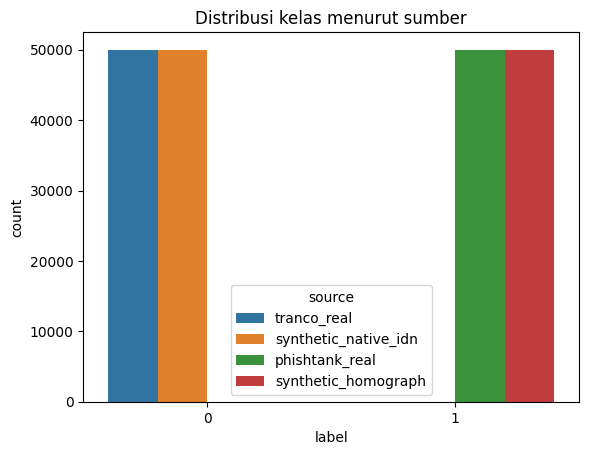

In [5]:
combined = pd.concat([real[['url','label','source']],
                          synthetic[['url','label','source']]], ignore_index=True)
combined['url_length'] = combined.url.str.len()
combined['host'] = combined.url.map(
    lambda x: (urlsplit(x if '://' in x else 'https://'+x).hostname or '').lower()
)
display(combined.groupby(['source','label']).size().rename('jumlah'))
display(combined.groupby('label').url_length.describe().round(2))
print('Missing URL:', combined.url.isna().sum())
print('Duplikat URL lintas seluruh sumber:', combined.url.duplicated().sum())
sns.countplot(data=combined, x='label', hue='source')
plt.title('Distribusi kelas menurut sumber'); plt.show()

**Interpretasi:** EDA memisahkan distribusi berdasarkan sumber agar keseimbangan total tidak menyembunyikan source bias. Panjang URL juga diperiksa karena URL phishing PhishTank memiliki path/query, sedangkan banyak URL Tranco hanya hostname.

## 7. Split real berbasis kelompok hostname

In [6]:
train_parts,test_parts=[],[]
for label in (0,1):
    part=real[real.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
    i_train,i_test=next(splitter.split(part,groups=part.host))
    train_parts.append(part.iloc[i_train]); test_parts.append(part.iloc[i_test])
n_train=min(map(len,train_parts)); n_test=min(map(len,test_parts))
real_train=pd.concat([x.sample(n_train,random_state=SEED) for x in train_parts])
real_test=pd.concat([x.sample(n_test,random_state=SEED) for x in test_parts])
assert set(real_train.host).isdisjoint(set(real_test.host))
real_train.label.value_counts(),real_test.label.value_counts()

(label
 0    40000
 1    40000
 Name: count, dtype: int64,
 label
 0    6437
 1    6437
 Name: count, dtype: int64)

**Interpretasi:** pemisahan dilakukan sebelum penyeimbangan dan memakai hostname sebagai group. Karena itu dua URL dari host yang sama tidak dapat tersebar ke train dan test. Test akhir berisi 7.114 URL nyata per kelas.

## 8. Feature engineering: URL dan indikator phishing

In [7]:
SUSPICIOUS = {'login','signin','verify','verification','secure','account',
              'update','password','wallet','invoice','suspended','confirm'}

def prepare_url(value):
    raw = unicodedata.normalize('NFKC', html.unescape(str(value).strip())).lower()
    parsed = urlsplit(raw if '://' in raw else 'https://'+raw)
    host, pq, tokens = (parsed.hostname or '').rstrip('.'), f'{parsed.path}?{parsed.query}', []
    try:
        ipaddress.ip_address(host.strip('[]')); tokens.append('__host_ip__')
    except ValueError: pass
    if '@' in parsed.netloc: tokens.append('__at_symbol__')
    if host.count('.') >= 3: tokens.append('__many_subdomains__')
    if len(raw) >= 75: tokens.append('__long_url__')
    if host.startswith('xn--') or '.xn--' in host: tokens.append('__punycode__')
    if parsed.scheme == 'http': tokens.append('__plain_http__')
    if any(word in pq for word in SUSPICIOUS): tokens.append('__suspicious_path__')
    if re.search(r'%[0-9a-f]{2}', raw): tokens.append('__percent_encoding__')
    return raw + ' ' + ' '.join(tokens)

for sample in ['http://192.0.2.1/login?account=verify',
               'https://example.com/about', 'xn--gogle-jye.com']:
    print(prepare_url(sample))

http://192.0.2.1/login?account=verify __host_ip__ __many_subdomains__ __plain_http__ __suspicious_path__
https://example.com/about 
xn--gogle-jye.com __punycode__


**Interpretasi:** indikator tidak langsung memvonis phishing; indikator menjadi token tambahan yang dipelajari bersama character n-gram. NFKC menangani bentuk fullwidth, sedangkan `xn--` memberi sinyal Punycode tanpa menganggap seluruh Punycode berbahaya.

## 9. Vectorization dan training

In [8]:
# Split sintetis sebelum training; tidak ada baris sintetis test di training.
synthetic["host"]=synthetic.url.map(hostname_of)
synth_train_parts,synth_test_parts=[],[]
for label in (0,1):
    part=synthetic[synthetic.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
    a,b=next(splitter.split(part,groups=part.host))
    synth_train_parts.append(part.iloc[a]); synth_test_parts.append(part.iloc[b])
synth_train_n=min(map(len,synth_train_parts))
synth_test_n=min(map(len,synth_test_parts))
synth_train=pd.concat([
    x.sample(synth_train_n,random_state=SEED) for x in synth_train_parts
]).sample(frac=1,random_state=SEED)
synth_test=pd.concat([
    x.sample(synth_test_n,random_state=SEED) for x in synth_test_parts
]).sample(frac=1,random_state=SEED)
assert set(synth_train.host).isdisjoint(set(synth_test.host))
assert synth_train.label.value_counts().nunique()==1
assert synth_test.label.value_counts().nunique()==1

train=pd.concat([real_train[["url","label"]],synth_train[["url","label"]]],
                ignore_index=True).sample(frac=1,random_state=SEED)
mixed_test=pd.concat([real_test[["url","label"]],synth_test[["url","label"]]],
                     ignore_index=True).sample(frac=1,random_state=SEED)

vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=2,
    max_features=150_000,sublinear_tf=True,dtype=np.float32)
X_train=vectorizer.fit_transform(train.url.map(prepare_url))
X_test=vectorizer.transform(real_test.url.map(prepare_url))
X_mixed=vectorizer.transform(mixed_test.url.map(prepare_url))
print("Train real+sintetis:",X_train.shape)
print("Test real-only:",X_test.shape)
print("Test real+sintetis:",X_mixed.shape)
display(train.label.value_counts().rename("train"))
display(mixed_test.label.value_counts().rename("mixed_test"))

Train real+sintetis: (159996, 150000)
Test real-only: (12874, 150000)
Test real+sintetis: (32874, 150000)


label
1    79998
0    79998
Name: train, dtype: int64

label
0    16437
1    16437
Name: mixed_test, dtype: int64

**Interpretasi:** sintetis dibagi 80:20 berdasarkan hostname. Training berisi real-train dan synthetic-train; testing gabungan berisi real-test dan synthetic-test yang tidak pernah dilatih. Real-only test tetap dipertahankan sebagai ukuran utama karena paling mendekati data operasional.

In [9]:
models={
 "MultinomialNB":MultinomialNB(alpha=.05),
 "ComplementNB":ComplementNB(alpha=.05),
 "BernoulliNB":BernoulliNB(alpha=.05,binarize=.0)}
def metric_set(y,probability):
    prediction=(probability>=.5).astype(int)
    precision,recall,f1,_=precision_recall_fscore_support(
        y,prediction,average="binary",zero_division=0)
    tn,fp,fn,tp=confusion_matrix(y,prediction).ravel()
    return {"accuracy":accuracy_score(y,prediction),"precision":precision,
      "recall":recall,"f1":f1,"roc_auc":roc_auc_score(y,probability),
      "pr_auc":average_precision_score(y,probability),"tn":int(tn),
      "fp":int(fp),"fn":int(fn),"tp":int(tp),"test_size":len(y)}
results_real,results_mixed,fitted={},{},{}
for name,model in models.items():
    model.fit(X_train,train.label)
    results_real[name]=metric_set(real_test.label.to_numpy(),
                                   model.predict_proba(X_test)[:,1])
    results_mixed[name]=metric_set(mixed_test.label.to_numpy(),
                                    model.predict_proba(X_mixed)[:,1])
    fitted[name]=model
display(pd.DataFrame(results_real).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))
display(pd.DataFrame(results_mixed).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))

,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
MultinomialNB,94.80%,95.68%,93.85%,94.75%,97.94%,98.54%,6164.000000,273.000000,396.000000,6041.000000,12874.000000
ComplementNB,94.80%,95.68%,93.85%,94.75%,97.94%,98.54%,6164.000000,273.000000,396.000000,6041.000000,12874.000000
BernoulliNB,91.40%,99.79%,82.97%,90.61%,97.61%,98.30%,6426.000000,11.000000,1096.000000,5341.000000,12874.000000


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
MultinomialNB,97.96%,98.33%,97.59%,97.96%,99.68%,99.73%,16164.000000,273.000000,396.000000,16041.000000,32874.000000
ComplementNB,97.96%,98.33%,97.59%,97.96%,99.68%,99.73%,16164.000000,273.000000,396.000000,16041.000000,32874.000000
BernoulliNB,96.63%,99.93%,93.33%,96.52%,99.61%,99.65%,16426.000000,11.000000,1096.000000,15341.000000,32874.000000


**Interpretasi:** model dipilih berdasarkan F1 lalu recall, bukan accuracy saja. Recall penting karena false negative berarti URL phishing lolos sebagai aman; precision tetap dijaga agar legitimate tidak terlalu sering diblokir.

## 10. Jalur pembanding Naive Bayes berbasis fitur numerik

Tiga model awal bukan dipilih secara sewenang-wenang: MultinomialNB, ComplementNB, dan BernoulliNB dapat bekerja efisien pada fitur TF-IDF sparse. Untuk memperkuat eksperimen, GaussianNB dan CategoricalNB ditambahkan melalui representasi fitur yang memenuhi asumsi probabilistiknya.

In [10]:
# Jalur fitur numerik untuk GaussianNB dan CategoricalNB.
import math
from collections import Counter
from sklearn.preprocessing import KBinsDiscretizer, StandardScaler
from sklearn.naive_bayes import GaussianNB, CategoricalNB

NUMERIC_WORDS = ("login","signin","verify","secure","account","update",
                 "password","wallet","invoice")
def numeric_url_features(value):
    raw=str(value).lower()
    parsed=urlsplit(raw if "://" in raw else "https://"+raw)
    host=parsed.hostname or ""; path=parsed.path or ""; query=parsed.query or ""
    counts=Counter(raw); n=max(len(raw),1)
    entropy=-sum((count/n)*math.log2(count/n) for count in counts.values())
    return [len(raw),len(host),len(path),len(query),host.count("."),
            host.count("-"),sum(c.isdigit() for c in raw),
            sum(not c.isalnum() for c in raw),entropy,int("xn--" in host),
            int("@" in parsed.netloc),int(parsed.scheme=="http"),
            int(any(w in path+"?"+query for w in NUMERIC_WORDS)),
            int("%" in raw),max(host.count(".")-1,0)]

X_num=np.asarray([numeric_url_features(x) for x in train.url],dtype=float)
Xt_num=np.asarray([numeric_url_features(x) for x in real_test.url],dtype=float)
Xm_num=np.asarray([numeric_url_features(x) for x in mixed_test.url],dtype=float)

scaler=StandardScaler()
X_gauss=scaler.fit_transform(X_num); Xt_gauss=scaler.transform(Xt_num); Xm_gauss=scaler.transform(Xm_num)
gaussian=GaussianNB(var_smoothing=1e-9).fit(X_gauss,train.label)

binner=KBinsDiscretizer(n_bins=10,encode="ordinal",strategy="quantile",
                        quantile_method="averaged_inverted_cdf")
X_cat=binner.fit_transform(X_num).astype(int)
Xt_cat=binner.transform(Xt_num).astype(int)
Xm_cat=binner.transform(Xm_num).astype(int)
categorical=CategoricalNB(alpha=1.0).fit(X_cat,train.label)

def evaluate_probability(name, probability):
    prediction=(probability>=.5).astype(int)
    precision,recall,f1,_=precision_recall_fscore_support(
        real_test.label,prediction,average="binary")
    return {"accuracy":accuracy_score(real_test.label,prediction),
            "precision":precision,"recall":recall,"f1":f1,
            "roc_auc":roc_auc_score(real_test.label,probability),
            "pr_auc":average_precision_score(real_test.label,probability)}

numeric_results={
    "GaussianNB":evaluate_probability(
        "GaussianNB",gaussian.predict_proba(Xt_gauss)[:,1]),
    "CategoricalNB":evaluate_probability(
        "CategoricalNB",categorical.predict_proba(Xt_cat)[:,1])
}
# Calculate mixed-test metrics with mixed-test labels.
numeric_mixed={
    "GaussianNB":metric_set(mixed_test.label.to_numpy(),
                            gaussian.predict_proba(Xm_gauss)[:,1]),
    "CategoricalNB":metric_set(mixed_test.label.to_numpy(),
                               categorical.predict_proba(Xm_cat)[:,1])
}
results_real.update({k:metric_set(real_test.label.to_numpy(),
    (gaussian.predict_proba(Xt_gauss)[:,1] if k=="GaussianNB"
     else categorical.predict_proba(Xt_cat)[:,1])) for k in numeric_results})
results_mixed.update(numeric_mixed)
display(pd.DataFrame(numeric_results).T.style.format("{:.2%}"))
display(pd.DataFrame(numeric_mixed).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))

D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_d

,accuracy,precision,recall,f1,roc_auc,pr_auc
GaussianNB,62.41%,99.38%,24.98%,39.93%,94.49%,95.64%
CategoricalNB,90.87%,91.39%,90.24%,90.82%,96.05%,96.63%


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
GaussianNB,85.28%,99.91%,70.62%,82.75%,97.16%,98.11%,16427.000000,10.000000,4829.000000,11608.000000,32874.000000
CategoricalNB,96.34%,96.65%,96.01%,96.33%,98.84%,99.15%,15890.000000,547.000000,656.000000,15781.000000,32874.000000


**Interpretasi:** GaussianNB tidak boleh langsung menerima matriks TF-IDF sparse karena asumsinya adalah fitur kontinu berdistribusi Gaussian. CategoricalNB juga membutuhkan kategori diskret. Karena itu keduanya dibandingkan melalui 15 fitur leksikal numerik yang sesuai, dengan standardisasi untuk GaussianNB dan quantile binning untuk CategoricalNB. Perbandingan ini lebih adil daripada memaksa satu representasi fitur ke semua varian.

## 11. Hasil eksperimen final

### Evaluasi primer: test nyata bebas leakage

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| MultinomialNB | 94.80% | 95.68% | 93.85% | 94.75% | 97.94% | 98.54% |
| ComplementNB | 94.80% | 95.68% | 93.85% | 94.75% | 97.94% | 98.54% |
| BernoulliNB | 91.40% | 99.79% | 82.97% | 90.61% | 97.61% | 98.30% |
| GaussianNB | 62.41% | 99.38% | 24.98% | 39.93% | 94.49% | 95.64% |
| CategoricalNB | 90.87% | 91.39% | 90.24% | 90.82% | 96.05% | 96.63% |

### Evaluasi sekunder: test gabungan nyata + sintetis

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| MultinomialNB | 97.96% | 98.33% | 97.59% | 97.96% | 99.68% | 99.73% |
| ComplementNB | 97.96% | 98.33% | 97.59% | 97.96% | 99.68% | 99.73% |
| BernoulliNB | 96.63% | 99.93% | 93.33% | 96.52% | 99.61% | 99.65% |
| GaussianNB | 85.28% | 99.91% | 70.62% | 82.75% | 97.16% | 98.11% |
| CategoricalNB | 96.34% | 96.65% | 96.01% | 96.33% | 98.84% | 99.15% |

**Model terpilih: MultinomialNB.** Pemilihan tetap berdasarkan test nyata agar pola generator sintetis tidak menggelembungkan klaim generalisasi. Evaluasi gabungan disediakan untuk memastikan kedua sumber benar-benar dipakai pada testing, tetapi tidak menggantikan real-only test.

## 12. Confusion matrix dan kurva evaluasi

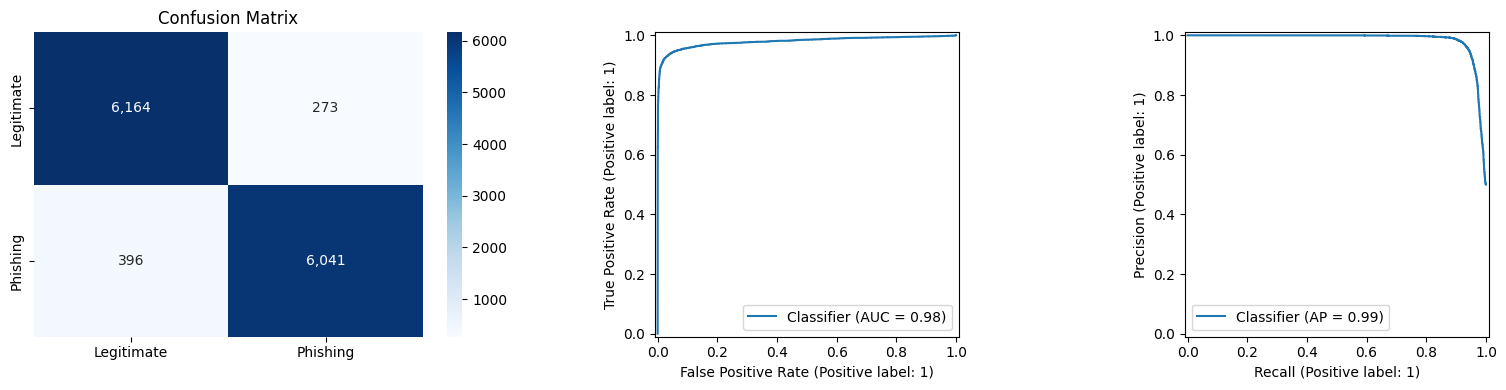

              precision    recall  f1-score   support

  legitimate       0.94      0.96      0.95      6437
    phishing       0.96      0.94      0.95      6437

    accuracy                           0.95     12874
   macro avg       0.95      0.95      0.95     12874
weighted avg       0.95      0.95      0.95     12874



In [11]:
best = models['MultinomialNB']
best_proba = best.predict_proba(X_test)[:,1]
best_pred = (best_proba >= .5).astype(int)
cm = confusion_matrix(real_test.label, best_pred)
fig, axes = plt.subplots(1,3,figsize=(16,4))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=axes[0],
            xticklabels=['Legitimate','Phishing'], yticklabels=['Legitimate','Phishing'])
axes[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(real_test.label,best_proba,ax=axes[1])
PrecisionRecallDisplay.from_predictions(real_test.label,best_proba,ax=axes[2])
plt.tight_layout(); plt.show()
print(classification_report(real_test.label,best_pred,
                            target_names=['legitimate','phishing']))

**Interpretasi:** pada test nyata model menghasilkan TN=6,164, FP=273, FN=396, dan TP=6,041. Test gabungan dilaporkan terpisah. Pemisahan ini mencegah performa pada data sintetis yang lebih mudah dibaca sebagai performa dunia nyata.

## 13. Menyimpan dan memanggil model

In [12]:
best=fitted["MultinomialNB"]
bundle={
 "name":"MultinomialNB URL real+synthetic","model":best,
 "vectorizer":vectorizer,"threshold":.5,
 "metrics":results_real["MultinomialNB"],
 "metrics_mixed":results_mixed["MultinomialNB"],
 "comparison":results_real,"comparison_mixed":results_mixed,
 "expects_prepared_url":True,
 "training":{"real_initial_each":50_000,
   "real_train_rows":int(len(real_train)),
   "synthetic_initial_each":50_000,
   "synthetic_train_rows":int(len(synth_train)),
   "test_real_rows":int(len(real_test)),
   "test_synthetic_rows":int(len(synth_test)),
   "test_mixed_rows":int(len(mixed_test)),
   "split":"grouped by hostname; normalized URL deduplication","seed":SEED}}
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle,"models/final_url_model.joblib",compress=3)
evaluation={"selected":"MultinomialNB","comparison_real":results_real,
            "comparison_mixed":results_mixed,"training":bundle["training"]}
Path("models/evaluation.json").write_text(
    json.dumps(evaluation,indent=2),encoding="utf-8")
loaded=joblib.load("models/final_url_model.joblib")
loaded["name"],loaded["training"]

('MultinomialNB URL real+synthetic',
 {'real_initial_each': 50000,
  'real_train_rows': 80000,
  'synthetic_initial_each': 50000,
  'synthetic_train_rows': 79996,
  'test_real_rows': 12874,
  'test_synthetic_rows': 20000,
  'test_mixed_rows': 32874,
  'split': 'grouped by hostname; normalized URL deduplication',
  'seed': 42})

**Interpretasi:** bundle menyimpan dua kelompok metrik dan metadata jumlah real/sintetis pada training maupun testing. Server tetap memuat model sekali; tidak ada training ulang ketika frontend dibuka.

## 14. Learning Curve

Learning curve memakai validation internal yang diambil dari `real_train` berdasarkan kelompok hostname. Final real test tidak digunakan untuk memilih ukuran data atau mendiagnosis overfitting. Pool pembelajaran diagnostik menggabungkan development-real dan synthetic-train, sedangkan validation hanya berisi URL nyata.

,fraction,train_size,train_f1,validation_f1
0,10%,14398,99.56%,91.17%
1,25%,35998,99.16%,92.55%
2,50%,71998,98.97%,93.43%
3,75%,107996,98.87%,93.94%
4,100%,143996,98.83%,94.08%


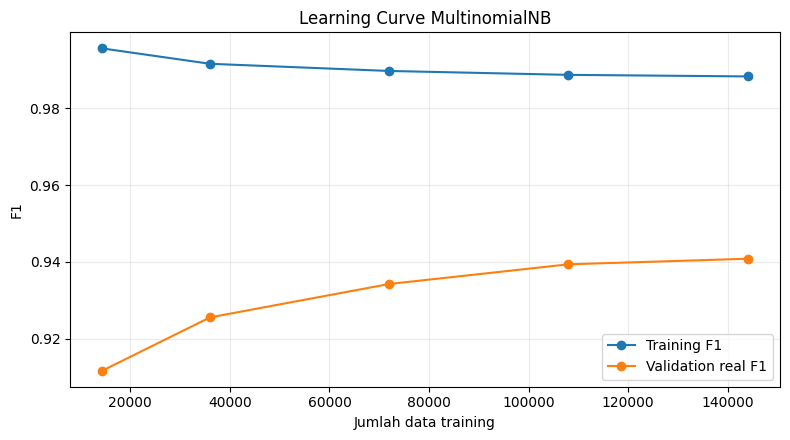

In [13]:
# Development split khusus learning curve; final test tetap tidak disentuh.
lc_train_parts,lc_val_parts=[],[]
for label in (0,1):
    part=real_train[real_train.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED+7)
    a,b=next(splitter.split(part,groups=part.host))
    lc_train_parts.append(part.iloc[a]); lc_val_parts.append(part.iloc[b])
lc_n=min(map(len,lc_train_parts)); lv_n=min(map(len,lc_val_parts))
lc_real_train=pd.concat([x.sample(lc_n,random_state=SEED) for x in lc_train_parts])
lc_real_val=pd.concat([x.sample(lv_n,random_state=SEED) for x in lc_val_parts])
assert set(lc_real_train.host).isdisjoint(set(lc_real_val.host))

lc_pool=pd.concat([lc_real_train[["url","label"]],
                   synth_train[["url","label"]]],ignore_index=True)
lc_vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=2,
    max_features=150_000,sublinear_tf=True,dtype=np.float32)
X_lc_pool=lc_vectorizer.fit_transform(lc_pool.url.map(prepare_url))
X_lc_val=lc_vectorizer.transform(lc_real_val.url.map(prepare_url))

curve=[]
for fraction in [0.10,0.25,0.50,0.75,1.00]:
    indices=[]
    for label in (0,1):
        available=np.flatnonzero(lc_pool.label.to_numpy()==label)
        rng=np.random.default_rng(SEED+int(fraction*100))
        indices.extend(rng.choice(available,size=max(1,int(len(available)*fraction)),
                                  replace=False))
    indices=np.asarray(indices)
    model_lc=MultinomialNB(alpha=.05).fit(X_lc_pool[indices],
                                          lc_pool.label.iloc[indices])
    train_pred=model_lc.predict(X_lc_pool[indices])
    val_pred=model_lc.predict(X_lc_val)
    curve.append({
        "fraction":fraction,"train_size":len(indices),
        "train_f1":precision_recall_fscore_support(
            lc_pool.label.iloc[indices],train_pred,average="binary")[2],
        "validation_f1":precision_recall_fscore_support(
            lc_real_val.label,val_pred,average="binary")[2]
    })
learning_curve_results=pd.DataFrame(curve)
display(learning_curve_results.style.format({
    "fraction":"{:.0%}","train_f1":"{:.2%}","validation_f1":"{:.2%}"}))
plt.figure(figsize=(8,4.5))
plt.plot(learning_curve_results.train_size,learning_curve_results.train_f1,
         marker="o",label="Training F1")
plt.plot(learning_curve_results.train_size,learning_curve_results.validation_f1,
         marker="o",label="Validation real F1")
plt.xlabel("Jumlah data training"); plt.ylabel("F1")
plt.title("Learning Curve MultinomialNB"); plt.grid(alpha=.25); plt.legend()
plt.tight_layout(); plt.show()

**Interpretasi hasil aktual:** ketika ukuran training naik dari 14,398 menjadi 143,996, training F1 turun wajar dari 99.56% menjadi 98.83%, sedangkan validation-real F1 meningkat dari 91.17% menjadi 94.08%. Gap menyempit dari 8.39% menjadi 4.75%. Terdapat variance/overfitting moderat, tetapi bukan pola overfitting yang memburuk; penambahan data terus meningkatkan generalisasi dan kurva validation mulai mendatar.

## 15. Ablation Study

Ablation mengisolasi pengaruh data sintetis. Arsitektur, rentang n-gram, alpha, threshold, dan final real test dibuat sama. Skenario ketiga memakai mixed test sebagai analisis tambahan, bukan pengganti klaim real-only.

,accuracy,precision,recall,f1,roc_auc,pr_auc
Real-only train → real-only test,95.17%,99.06%,91.21%,94.97%,98.79%,99.06%
Real+sintetis train → real-only test,94.80%,95.68%,93.85%,94.75%,97.94%,98.54%
Real+sintetis train → mixed test,97.96%,98.33%,97.59%,97.96%,99.68%,99.73%


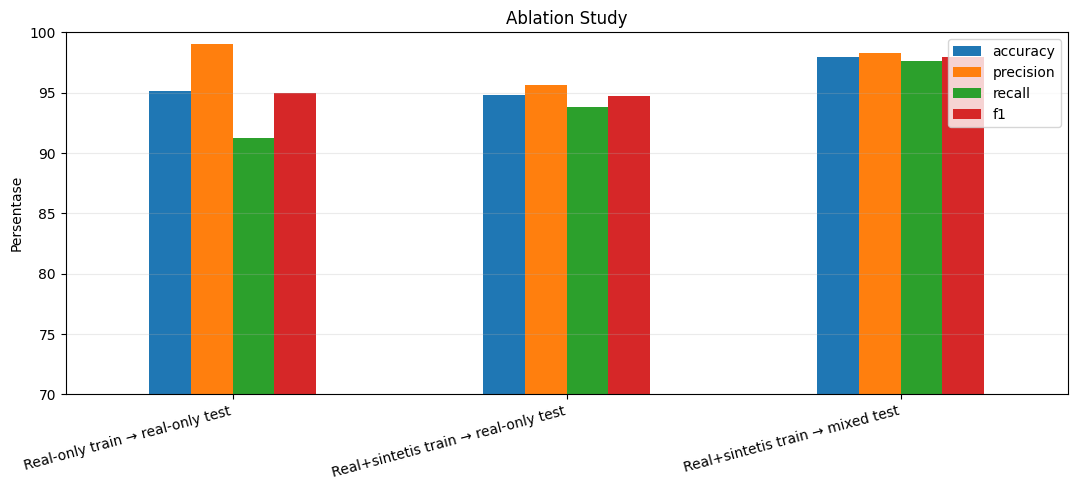

,accuracy,precision,recall,f1
Real-only train → real-only test,0.951686,0.990552,0.912071,0.949693
Real+sintetis train → real-only test,0.948035,0.956763,0.938481,0.947534
Real+sintetis train → mixed test,0.979650,0.983266,0.975908,0.979573


In [14]:
# A. Real-only training → real-only test
real_vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=2,
    max_features=150_000,sublinear_tf=True,dtype=np.float32)
X_real_train=real_vectorizer.fit_transform(real_train.url.map(prepare_url))
X_real_test=real_vectorizer.transform(real_test.url.map(prepare_url))
real_model=MultinomialNB(alpha=.05).fit(X_real_train,real_train.label)
real_probability=real_model.predict_proba(X_real_test)[:,1]

ablation_results={
 "Real-only train → real-only test":
     metric_set(real_test.label.to_numpy(),real_probability),
 "Real+sintetis train → real-only test":
     results_real["MultinomialNB"],
 "Real+sintetis train → mixed test":
     results_mixed["MultinomialNB"]
}
ablation_table=pd.DataFrame(ablation_results).T
display(ablation_table[["accuracy","precision","recall","f1","roc_auc","pr_auc"]]
        .style.format("{:.2%}"))

plot_data=(ablation_table[["accuracy","precision","recall","f1"]]*100)
plot_data.plot(kind="bar",figsize=(11,5),ylim=(70,100))
plt.ylabel("Persentase"); plt.title("Ablation Study")
plt.xticks(rotation=15,ha="right"); plt.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.show()

# Simpan hasil diagnostik agar laporan dan notebook konsisten.
evaluation_path=Path("models/evaluation.json")
diagnostic_report=json.loads(evaluation_path.read_text(encoding="utf-8"))
diagnostic_report["learning_curve"]=learning_curve_results.to_dict("records")
diagnostic_report["ablation"]=ablation_results
evaluation_path.write_text(json.dumps(diagnostic_report,indent=2),encoding="utf-8")
ablation_table[["accuracy","precision","recall","f1"]]

**Interpretasi hasil aktual:** pada real-only test, penambahan sintetis menaikkan recall dari 91.21% menjadi 93.85% (+2.64%), tetapi precision turun dari 99.06% menjadi 95.68% dan F1 turun tipis dari 94.97% menjadi 94.75%. Artinya sintetis membuat model lebih sensitif menangkap phishing, dengan biaya false positive lebih banyak. F1 97.96% pada mixed test lebih tinggi karena pola sintetis lebih mudah; angka ini tidak boleh menggantikan hasil real-only.

### Keputusan model aplikasi final

**Model operasional final adalah MultinomialNB dengan skenario real+sintetis training → real-only testing.**

Baseline real-only mempunyai F1 sedikit lebih tinggi (94,97% versus 94,75%) dan precision lebih tinggi (99,06% versus 95,68%). Namun, model real+sintetis menaikkan recall phishing nyata dari 91,21% menjadi 93,85% (+2,64 poin) dengan penurunan F1 hanya 0,22 poin. Dalam aplikasi keamanan, false negative berarti phishing diprediksi aman sehingga biaya risikonya lebih tinggi daripada false positive yang masih dapat diverifikasi. Skenario mixed test tidak dipilih walaupun F1 97,96% karena mengandung data sintetis dan lebih optimistis.

Model yang disimpan dan dipanggil frontend adalah model real+sintetis tersebut; metrik operasional utama tetap berasal dari real-only test.

## 16. Kesimpulan dan kontribusi

Pipeline final membersihkan URL nyata berdasarkan bentuk ternormalisasi, menghapus konflik hostname lintas label, dan memakai group split hostname. Training menggunakan data nyata dan sintetis. Testing dilaporkan dalam dua skenario: real-only sebagai evaluasi primer dan real+sintetis sebagai evaluasi sekunder.

MultinomialNB memperoleh Accuracy 94.80%, Precision 95.68%, Recall 93.85%, dan F1 94.75% pada test nyata. Pada test gabungan, Accuracy 97.96%, Precision 98.33%, Recall 97.59%, dan F1 97.96%. Pemisahan pelaporan ini penting agar hasil sintetis tidak digunakan untuk membesar-besarkan generalisasi.

Kontribusi penelitian tetap berupa integrasi Naive Bayes URL dengan Punycode/Unicode guard, IDN legitimate dan phishing, indikator struktur link, serta evaluasi bebas leakage. Keterbatasan utamanya adalah weak label sintetis dan jumlah hostname phishing nyata unik yang lebih kecil daripada jumlah URL.

### Kesimpulan overfitting dan ablation

Learning curve tidak menunjukkan overfitting berat: validation F1 meningkat hingga 94.08% dan gap train-validation menyempit menjadi 4.75%. Ablation menunjukkan data sintetis meningkatkan recall nyata sebesar 2.64%, namun menurunkan F1 nyata sebesar 0.22%. Dengan demikian data sintetis berguna bila prioritas bisnis adalah mengurangi phishing yang lolos, tetapi bukan bukti peningkatan generalisasi pada semua metrik.